# CyberDefense AI — Détection d'intrusion réseau multiclasse

**TP Cybersécurité — EPAC, GIT4/RII**

Ce notebook entraîne un réseau de neurones (MLP, PyTorch) à classer des flux réseau en 7 familles :
`Benign`, `DDoS`, `DoS`, `Botnet`, `Infiltration`, `Bruteforce`, `Web Attack`.

**Dataset** : [CSE-CIC-IDS2018](https://www.kaggle.com/datasets/dhoogla/csecicids2018) (version nettoyée,
Kaggle, utilisateur `dhoogla`) — 10 fichiers parquet, un par jour de capture / catégorie d'attaque,
déjà extraits en statistiques de flux via CICFlowMeter.

**Pourquoi ce dataset ?** Contrairement à des jeux de données où les colonnes sont spécifiques à un
réseau particulier, CSE-CIC-IDS2018 est construit à partir de **statistiques de flux génériques**
(durée, nombre de paquets, octets, IAT, flags TCP...) calculables sur n'importe quel réseau via
CICFlowMeter — condition nécessaire pour que ce modèle serve réellement dans le cadre du TP
(déploiement sur le PC de défense, avec capture + extraction + prédiction automatisées).

**Pourquoi un réseau de neurones (deep learning) plutôt qu'un modèle classique ?**
Avec ~6,6 millions de lignes et des interactions non linéaires entre des dizaines de features de flux,
un MLP capture plus facilement ces interactions qu'un modèle linéaire, tout en restant largement
moins coûteux à entraîner et à déployer qu'une architecture récurrente ou convolutive — inutiles ici
puisqu'on classe des flux indépendants (vecteurs de features), pas des séquences brutes de paquets.

**Important avant de committer ce notebook** : exécute-le entièrement de haut en bas (`Run All`) sur
Kaggle (GPU activé) avant de le pousser sur le dépôt Git, pour que toutes les sorties affichées soient
cohérentes avec le code actuel (en particulier la cellule de rééquilibrage des classes).


## 1. Chargement des données

On liste les fichiers parquet mis à disposition par Kaggle dans `/kaggle/input/`. Chaque fichier
correspond à une journée de capture et une catégorie d'attaque (DoS, DDoS, Bruteforce, Botnet,
Infiltration, Web Attack, plus du trafic normal `Benign` mélangé dans chacun).


In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
path = []

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        path.append(str(os.path.join(dirname, filename)))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md
print(path)
import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

['/kaggle/input/datasets/dhoogla/csecicids2018/Botnet-Friday-02-03-2018_TrafficForML_CICFlowMeter.parquet', '/kaggle/input/datasets/dhoogla/csecicids2018/Bruteforce-Wednesday-14-02-2018_TrafficForML_CICFlowMeter.parquet', '/kaggle/input/datasets/dhoogla/csecicids2018/DDoS1-Tuesday-20-02-2018_TrafficForML_CICFlowMeter.parquet', '/kaggle/input/datasets/dhoogla/csecicids2018/DDoS2-Wednesday-21-02-2018_TrafficForML_CICFlowMeter.parquet', '/kaggle/input/datasets/dhoogla/csecicids2018/DoS1-Thursday-15-02-2018_TrafficForML_CICFlowMeter.parquet', '/kaggle/input/datasets/dhoogla/csecicids2018/DoS2-Friday-16-02-2018_TrafficForML_CICFlowMeter.parquet', '/kaggle/input/datasets/dhoogla/csecicids2018/Infil1-Wednesday-28-02-2018_TrafficForML_CICFlowMeter.parquet', '/kaggle/input/datasets/dhoogla/csecicids2018/Infil2-Thursday-01-03-2018_TrafficForML_CICFlowMeter.parquet', '/kaggle/input/datasets/dhoogla/csecicids2018/Web1-Thursday-22-02-2018_TrafficForML_CICFlowMeter.parquet', '/kaggle/input/datasets/

## 2. Imports

Bibliothèques pour la manipulation de données (`pandas`, `numpy`), la visualisation (`matplotlib`,
`seaborn`), et l'entraînement du réseau de neurones (`torch`).


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
import torch
from torch import nn


## 3. Fusion des 10 fichiers

Les 10 fichiers sont chargés puis concaténés en un seul DataFrame. Chaque fichier garde son nom
d'origine (`dataName`) dans `datasetDict`, ce qui permet ensuite de vérifier la répartition
des données par fichier source (section suivante) avant de les fusionner définitivement.


In [3]:
dataName= ['Bonet', 'Bruteforce', 'DDOS1', 'DDOS2', 'DOS1', 'DOS2', 'Infil1', 'Infil2', 'Web1', 'Web2']
datasetDict ={}

for i in range (len(dataName)):
    datasetDict[dataName[i]] = pd.read_parquet(path[i])


df = pd.concat(datasetDict.values(), ignore_index=True)
    

Taille attendue après fusion : **6 659 532 lignes × 78 colonnes** (77 features de flux + la colonne
`Label`).


In [4]:
df.shape

(6659532, 78)

## 4. Répartition par fichier source

Avant toute analyse, on vérifie que les 10 fichiers contribuent dans des proportions cohérentes
(pas de fichier anormalement petit ou corrompu), et que le volume total correspond bien à la somme
attendue.


In [5]:
a=0
for i in datasetDict.keys():
    a += datasetDict[i].shape[0]

for i in datasetDict.keys():
    print(i , ":", datasetDict[i].shape[0], (datasetDict[i].shape[0]/a) * 100, "%")

Bonet : 771587 11.586204556115955 %
Bruteforce : 619346 9.300143013052569 %
DDOS1 : 954846 14.338034564591027 %
DDOS2 : 561396 8.429961745059563 %
DOS1 : 794812 11.934952786472081 %
DOS2 : 591873 8.887606516493953 %
Infil1 : 456873 6.8604370397199075 %
Infil2 : 249170 3.7415542113169513 %
Web1 : 830224 12.466701864335212 %
Web2 : 829405 12.454403702842782 %


## 5. Répartition des classes (avant regroupement)

Le dataset original contient 15 étiquettes fines. On observe ici un déséquilibre sévère :
`Benign` représente environ **80 %** des flux, tandis que certaines attaques (`SQL Injection`,
`DoS attacks-SlowHTTPTest`, `FTP-BruteForce`) représentent chacune moins de **0,001 %** — quelques
dizaines de lignes sur 6,6 millions. Un modèle entraîné directement sur ces 15 classes ignorerait
presque totalement les classes les plus rares. D'où le regroupement en familles d'attaques
(section suivante).


In [6]:
df['Label'].value_counts()/df.shape[0]

Label
Benign                      0.800208
DDoS attacks-LOIC-HTTP      0.086397
DDOS attack-HOIC            0.029861
DoS attacks-Hulk            0.021803
Bot                         0.021703
Infilteration               0.017791
SSH-Bruteforce              0.014122
DoS attacks-GoldenEye       0.006218
DoS attacks-Slowloris       0.001488
DDOS attack-LOIC-UDP        0.000260
Brute Force -Web            0.000085
Brute Force -XSS            0.000034
SQL Injection               0.000013
DoS attacks-SlowHTTPTest    0.000008
FTP-BruteForce              0.000008
Name: count, dtype: float64

## 6. Regroupement en familles d'attaques

On réduit les 15 étiquettes fines à **7 familles** plus robustes statistiquement : `Benign`, `DDoS`,
`DoS`, `Botnet`, `Infiltration`, `Bruteforce`, `Web Attack`. Ce regroupement a deux objectifs :

- **Donner un volume minimal à chaque classe** pour que le modèle puisse réellement apprendre à la
  reconnaître (certaines étiquettes fines comptaient moins de 100 exemples).
- **Refléter des familles d'attaques réellement distinctes en pratique** : du point de vue de la
  défense, différencier `DoS attacks-Hulk` de `DoS attacks-GoldenEye` apporte peu d'information
  utile ; les deux appellent la même réponse (atténuation DoS).


In [7]:
FAMILY_MAP = {
    "Benign": "Benign",
    "DDoS attacks-LOIC-HTTP": "DDoS",
    "DDOS attack-HOIC": "DDoS",
    "DDOS attack-LOIC-UDP": "DDoS",
    "DoS attacks-Hulk": "DoS",
    "DoS attacks-GoldenEye": "DoS",
    "DoS attacks-Slowloris": "DoS",
    "DoS attacks-SlowHTTPTest": "DoS",
    "Bot": "Botnet",
    "Infilteration": "Infiltration",
    "SSH-Bruteforce": "Bruteforce",
    "FTP-BruteForce": "Bruteforce",
    "Brute Force -Web": "Web Attack",
    "Brute Force -XSS": "Web Attack",
    "SQL Injection": "Web Attack",
}

df['Label'] = df['Label'].map(FAMILY_MAP)


## 7. Vérification des valeurs manquantes (NaN)

Avant tout nettoyage plus poussé, on vérifie l'absence de valeurs manquantes — un dataset déjà
nettoyé par CICFlowMeter et par le pipeline de préparation Kaggle ne devrait en théorie en contenir
aucune. Résultat attendu : **0 NaN** sur l'ensemble des 78 colonnes.


In [8]:
df.isna().sum()          # nombre de NaN par colonne
df.isna().sum().sum()    # total de NaN dans tout le dataset
(df.isna().sum() / len(df) * 100).sort_values(ascending=False)  # % par colonne

Protocol                    0.0
Flow Duration               0.0
Total Fwd Packets           0.0
Total Backward Packets      0.0
Fwd Packets Length Total    0.0
                           ... 
Idle Mean                   0.0
Idle Std                    0.0
Idle Max                    0.0
Idle Min                    0.0
Label                       0.0
Length: 78, dtype: float64

Vérification visuelle sur un échantillon de 2000 lignes (une carte complète sur 6,6M lignes
dépasserait la limite de résolution de matplotlib) — doit apparaître uniformément vide de valeurs
manquantes.


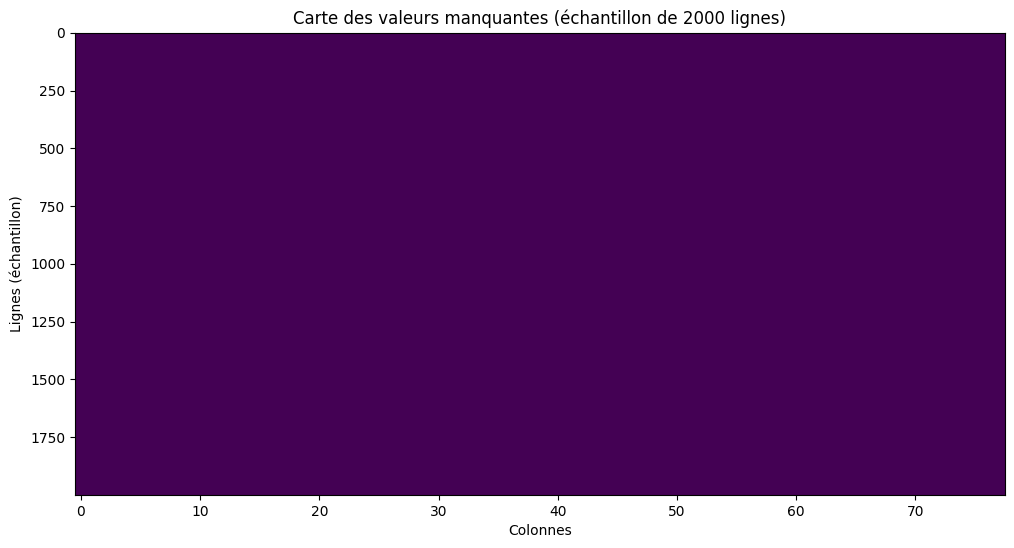

In [9]:
plt.figure(figsize=(12, 6))
plt.imshow(df.sample(2000, random_state=42).isna(), aspect='auto', cmap='viridis')
plt.xlabel("Colonnes")
plt.ylabel("Lignes (échantillon)")
plt.title("Carte des valeurs manquantes (échantillon de 2000 lignes)")
plt.show()

## 8. Vérification des valeurs infinies

Certaines colonnes de flux sont des ratios (ex. `Flow Bytes/s`, `Flow Packets/s`) qui peuvent
théoriquement produire des valeurs infinies si la durée du flux est nulle. On vérifie qu'aucune
colonne numérique n'en contient.


In [10]:
n_inf = np.isinf(df.select_dtypes(include=[np.number])).sum()
print(n_inf[n_inf > 0])          # colonnes concernées
print(np.isinf(df.select_dtypes(include=[np.number])).sum().sum())  # total

Series([], dtype: int64)
0


## 9. Audit des types de colonnes

On liste le type de chaque colonne. Cet audit sert à repérer d'éventuelles colonnes identifiantes
(IP, port, timestamp, Flow ID) qui introduiraient une **fuite de données** (data leakage) si elles
étaient laissées dans les features — ce n'est pas le cas ici, cette version nettoyée du dataset ne
contient que des statistiques de flux et l'étiquette.


In [11]:
list1 = df.columns
list2 = df.dtypes
for i in range (len(list2)):
    print(list1[i], ":", list2[i])

Protocol : int8
Flow Duration : int64
Total Fwd Packets : int32
Total Backward Packets : int32
Fwd Packets Length Total : int32
Bwd Packets Length Total : float64
Fwd Packet Length Max : int32
Fwd Packet Length Min : int16
Fwd Packet Length Mean : float32
Fwd Packet Length Std : float32
Bwd Packet Length Max : int32
Bwd Packet Length Min : int16
Bwd Packet Length Mean : float32
Bwd Packet Length Std : float32
Flow Bytes/s : float64
Flow Packets/s : float64
Flow IAT Mean : float32
Flow IAT Std : float32
Flow IAT Max : float64
Flow IAT Min : float64
Fwd IAT Total : float64
Fwd IAT Mean : float32
Fwd IAT Std : float32
Fwd IAT Max : float64
Fwd IAT Min : float64
Bwd IAT Total : float64
Bwd IAT Mean : float32
Bwd IAT Std : float32
Bwd IAT Max : float64
Bwd IAT Min : float64
Fwd PSH Flags : int8
Bwd PSH Flags : int8
Fwd URG Flags : int8
Bwd URG Flags : int8
Fwd Header Length : int32
Bwd Header Length : int32
Fwd Packets/s : float32
Bwd Packets/s : float32
Packet Length Min : int16
Packet Len

/tmp/ipykernel_24/4011566393.py:4: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(list1[i], ":", list2[i])


## 10. Statistiques descriptives globales

Vue d'ensemble (moyenne, écart-type, min, max, quartiles) de toutes les colonnes numériques. Cette
étape sert à repérer trois choses qu'on creuse dans les sections suivantes : une forte asymétrie
(skewness), des valeurs négatives suspectes, et des colonnes à variance nulle (inutiles).


In [12]:
df.describe().T                                    # vue d'ensemble de toutes les colonnes en une fois

,count,mean,std,min,25%,50%,75%,max
Protocol,6659532.0,8.162630e+00,4.544056e+00,0.000000e+00,6.0,6.0,6.0,1.700000e+01
Flow Duration,6659532.0,1.460836e+07,7.704883e+08,-9.190110e+11,8064.0,695576.0,5150532.5,1.200000e+08
Total Fwd Packets,6659532.0,5.051647e+01,2.373863e+03,1.000000e+00,2.0,3.0,7.0,3.096290e+05
Total Backward Packets,6659532.0,8.055791e+00,1.975216e+02,0.000000e+00,1.0,2.0,5.0,1.231180e+05
Fwd Packets Length Total,6659532.0,1.973359e+03,9.702574e+04,0.000000e+00,20.0,97.0,935.0,1.443918e+08
...,...,...,...,...,...,...,...,...
Active Min,6659532.0,8.270550e+04,1.422508e+06,0.000000e+00,0.0,0.0,0.0,1.140000e+08
Idle Mean,6659532.0,7.218760e+06,4.104132e+08,0.000000e+00,0.0,0.0,0.0,3.955714e+11
Idle Std,6659532.0,4.952408e+05,2.641359e+08,0.000000e+00,0.0,0.0,0.0,2.622479e+11
Idle Max,6659532.0,8.054734e+06,9.762279e+08,0.000000e+00,0.0,0.0,0.0,9.797810e+11


## 11. Asymétrie des distributions

Les statistiques de flux réseau sont naturellement très asymétriques (quelques flux très longs ou
très volumineux, une majorité de flux courts) — ce n'est pas une anomalie à corriger, mais un
rappel que ces features ne suivent pas une loi normale. Le `StandardScaler` utilisé plus loin
centre/réduit les données sans supposer de normalité, et le réseau de neurones (avec BatchNorm)
est robuste à ce type de distribution.


In [13]:
df.select_dtypes('number').skew().sort_values(ascending=False)  # asymétrie de toutes les colonnes, triée

Idle Min                  2223.907540
Packet Length Variance    1786.340576
Idle Max                   853.271199
Idle Std                   837.811829
Idle Mean                  810.101685
                             ...     
Flow IAT Min              -749.437086
Flow Duration             -921.875314
Fwd IAT Total             -921.881212
Fwd IAT Mean             -2167.566162
Flow IAT Mean            -2167.710693
Length: 77, dtype: float64

## 12. Colonnes à variance nulle

On compte combien de colonnes n'ont qu'une seule valeur unique sur tout le dataset — ces colonnes
n'apportent strictement aucune information au modèle et seront supprimées (section 15).


In [14]:
print((df.select_dtypes('number').std() == 0).sum() )     # combien de colonnes à variance nulle (inutiles)

8


## 13. Détection des valeurs aberrantes (négatives)

On recherche les colonnes numériques contenant des valeurs négatives suspectes. Deux cas très
différents apparaissent :

- **`Flow Duration`, `Flow IAT *`, `Fwd IAT *`, `Flow Packets/s`** : une poignée de lignes (moins de
  15 chacune, sur 6,6 millions) ont des valeurs négatives — probablement des artefacts de capture
  (horodatages incohérents). Elles seront supprimées.
- **`Init Fwd Win Bytes` et `Init Bwd Win Bytes`** : des centaines de milliers de valeurs à `-1`.
  **Ce n'est pas une anomalie** : `-1` est la convention CICFlowMeter pour « taille de fenêtre TCP
  non observée » (flux UDP, ou flux trop court pour capturer un SYN) — une valeur légitime et
  fréquente, qu'il ne faut surtout pas filtrer comme les autres.


In [15]:
neg_counts = (df.select_dtypes('number') < 0).sum()
print(neg_counts[neg_counts > 0])

Flow Duration              14
Flow Packets/s             14
Flow IAT Mean              14
Flow IAT Max                3
Flow IAT Min               15
Fwd IAT Total              14
Fwd IAT Mean               14
Fwd IAT Max                 3
Fwd IAT Min                15
Init Fwd Win Bytes    1464316
Init Bwd Win Bytes    2590018
dtype: int64


On supprime donc uniquement les lignes où une colonne de durée/IAT est négative, en excluant
explicitement `Init Fwd/Bwd Win Bytes` de ce filtre (perte attendue : une quinzaine de lignes sur
6,6 millions, négligeable).


In [16]:
cols_duree_iat = [
    'Flow Duration', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Max', 'Flow IAT Min',
    'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Max', 'Fwd IAT Min'
]
# Init Fwd/Bwd Win Bytes volontairement exclus : -1 y est une valeur valide

n_before = len(df)
mask_valid = (df[cols_duree_iat] >= 0).all(axis=1)
df = df[mask_valid]

print(f"Lignes supprimées : {n_before - len(df)} (sur {n_before})")

Lignes supprimées : 15 (sur 6659532)


Vérification post-filtrage : les statistiques descriptives générales restent cohérentes.


In [17]:
df.describe().T   

,count,mean,std,min,25%,50%,75%,max
Protocol,6659517.0,8.162648e+00,4.544046e+00,0.0,6.0,6.0,6.0,17.0
Flow Duration,6659517.0,1.552372e+07,3.304803e+07,1.0,8064.0,695591.0,5150557.0,120000000.0
Total Fwd Packets,6659517.0,5.051639e+01,2.373866e+03,1.0,2.0,3.0,7.0,309629.0
Total Backward Packets,6659517.0,8.055808e+00,1.975218e+02,0.0,1.0,2.0,5.0,123118.0
Fwd Packets Length Total,6659517.0,1.973363e+03,9.702585e+04,0.0,20.0,97.0,935.0,144391846.0
...,...,...,...,...,...,...,...,...
Active Min,6659517.0,8.270569e+04,1.422509e+06,0.0,0.0,0.0,0.0,114000000.0
Idle Mean,6659517.0,6.699990e+06,1.888944e+07,0.0,0.0,0.0,0.0,120000000.0
Idle Std,6659517.0,1.658489e+05,1.774792e+06,0.0,0.0,0.0,0.0,75900000.0
Idle Max,6659517.0,6.849188e+06,1.912947e+07,0.0,0.0,0.0,0.0,120000000.0


## 14. Colonnes constantes

On identifie précisément les 8 colonnes à variance nulle repérées en section 12, et on confirme
qu'elles n'ont qu'une seule valeur unique sur tout le dataset (souvent `0`, parfois liées aux
statistiques de "bulk transfer" que CICFlowMeter ne remplit pas dans ce contexte de capture).


In [18]:
zero_var_cols = df.select_dtypes('number').columns[df.select_dtypes('number').std() == 0]
print(list(zero_var_cols))

df[zero_var_cols].iloc[0]       # voir la valeur constante de chacune
df[zero_var_cols].nunique()     # confirme qu'il n'y a bien qu'une seule valeur unique par colonne

['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']


Bwd PSH Flags           1
Bwd URG Flags           1
Fwd Avg Bytes/Bulk      1
Fwd Avg Packets/Bulk    1
Fwd Avg Bulk Rate       1
Bwd Avg Bytes/Bulk      1
Bwd Avg Packets/Bulk    1
Bwd Avg Bulk Rate       1
dtype: int64

## 15. Suppression des colonnes constantes

Ces colonnes sont supprimées : elles ne peuvent apporter aucun pouvoir discriminant au modèle
(une colonne constante a une contribution nulle dans n'importe quel modèle linéaire ou nonlinéaire).
On passe ainsi de 78 à **70 colonnes** (69 features + `Label`).


In [19]:
df = df.drop(columns=zero_var_cols)
print(df.shape)   # tu dois passer de 78 à 70 colonnes de features (+ Label)

(6659517, 70)


## 16. Rééquilibrage des classes

C'est l'étape la plus déterminante du projet. Après regroupement en familles, `Benign` reste
largement majoritaire (plusieurs millions de lignes) face à des familles d'attaques beaucoup plus
rares (`Web Attack` ne compte que 882 lignes). Entraîner directement sur cette distribution produit
un modèle qui prédit presque toujours `Benign` et ignore les attaques rares.

**Stratégie retenue : plafonner chaque classe à `MAX_PER_CLASS` lignes** (sous-échantillonnage
aléatoire, `random_state=42` pour la reproductibilité), plutôt que de réduire uniquement `Benign`.
Réduire `Benign` seul sans plafonner les autres classes changerait simplement la classe majoritaire
(`DDoS` deviendrait majoritaire à la place) — ça ne résout rien, ça déplace le problème.

Le seuil est fixé à **`MAX_PER_CLASS = 800 000`**, choisi volontairement haut pour `Benign` : les
attaques de type DoS/DDoS génèrent un trafic qui, statistiquement, ressemble par endroits à du
trafic normal à fort volume — garder une marge large de trafic `Benign` authentique limite le
risque que le modèle confonde un pic de trafic légitime avec une attaque volumétrique.

Ce rééquilibrage est complété plus loin par une pondération de la fonction de perte
(`class_weight="balanced"`, plafonnée) plutôt que par un rééquilibrage pur, pour ne pas sur-corriger
au point de dégrader la précision sur `Benign` (la classe la plus fréquente en conditions réelles).

**Sortie attendue avec `MAX_PER_CLASS = 800 000`** : `Benign` plafonné à 800 000 (seule classe
affectée par le seuil, les autres étant déjà sous ce seuil), total **≈ 2 130 524 lignes**.


In [20]:
MAX_PER_CLASS = 800_000

def cap_group(g):
    return g.sample(n=min(len(g), MAX_PER_CLASS), random_state=42)

df = df.groupby('Label', group_keys=False).apply(cap_group)
df.to_parquet('/kaggle/working/dataset_clean_capped.parquet')
print(df['Label'].value_counts())
print(df.shape)

/tmp/ipykernel_24/1240667990.py:6: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df = df.groupby('Label', group_keys=False).apply(cap_group)


Label
Benign          800000
DDoS            775955
DoS             196568
Botnet          144535
Infiltration    118483
Bruteforce       94101
Web Attack         882
Name: count, dtype: int64
(2130524, 70)


## 17. Encodage de l'étiquette et préparation des features

`LabelEncoder` transforme les 7 noms de familles en entiers (0 à 6) attendus par `CrossEntropyLoss`
de PyTorch. Les features sont converties en `float32` (plutôt que le `float64` par défaut) pour
diviser par deux l'empreinte mémoire — un point critique vu la taille du dataset (plusieurs millions
de lignes), qui a provoqué des plantages mémoire sur Kaggle avant cette optimisation.

`FEATURE_COLUMNS` fige l'ordre exact des colonnes utilisées à l'entraînement : ce même ordre devra
être respecté strictement lors de toute prédiction future (sauvegardé dans
`feature_columns.joblib`).


In [21]:
from sklearn.preprocessing import LabelEncoder
import numpy as np

le = LabelEncoder()
y = le.fit_transform(df['Label'])
X = df.drop(columns=['Label']).astype('float32').values

FEATURE_COLUMNS = df.drop(columns=['Label']).columns.tolist()
N_CLASSES = len(le.classes_)
print("Classes :", list(le.classes_))

Classes : ['Benign', 'Botnet', 'Bruteforce', 'DDoS', 'DoS', 'Infiltration', 'Web Attack']


## 18. Architecture du modèle

Un perceptron multicouche (MLP) simple : deux couches cachées (128 puis 64 neurones), avec
`BatchNorm1d` (stabilise l'entraînement face à des features d'échelles très différentes) et
`Dropout` (régularisation contre le surapprentissage) après chaque couche. Cette architecture et ces
hyperparamètres (`hidden=(128, 64)`, `lr=0.0001`) sont le résultat d'une recherche d'hyperparamètres
par validation croisée (grid search, 5-fold stratifié, menée séparément — voir le notebook de
recherche d'hyperparamètres et la documentation du modèle pour le détail des 12 configurations
testées).


In [22]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score, classification_report
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import torch
import torch.nn as nn
import gc

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

le = LabelEncoder()
y = le.fit_transform(df['Label'])
X = df.drop(columns=['Label']).astype('float32').values
N_CLASSES = len(le.classes_)
print("Classes :", list(le.classes_))

class CyberDefenseMLP(nn.Module):
    def __init__(self, n_features, n_classes, hidden=(128, 64), dropout=0.3):
        super().__init__()
        layers = []
        prev = n_features
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, n_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

cuda
Classes : ['Benign', 'Botnet', 'Bruteforce', 'DDoS', 'DoS', 'Infiltration', 'Web Attack']


## 19. Entraînement diagnostic : courbes d'apprentissage et vérification de l'overfitting

Avant l'entraînement final, on entraîne le modèle sur un split train/validation simple (80/20,
stratifié) — pas de validation croisée complète ici, celle-ci ayant déjà servi à sélectionner les
hyperparamètres en amont. L'objectif de cette étape est uniquement de **tracer les courbes de perte
et de F1 macro (train vs validation) à chaque epoch**, pour vérifier que le modèle ne surapprend
pas avant de l'entraîner sur 100 % des données.

Un échantillon de 50 000 lignes du train est utilisé pour évaluer le F1 train à chaque epoch (plutôt
que les ~1,7M lignes complètes), pour accélérer l'évaluation sans fausser la mesure.

**Signal d'overfitting à surveiller** : un écart croissant entre `train_f1` et `val_f1` au fil des
epochs. **Ce n'est pas la valeur absolue du val_loss plus bas que le train_loss qui indique un
surapprentissage** — c'est normal et attendu ici, causé par le comportement différent de `Dropout`
et `BatchNorm` en mode entraînement (actifs, bruit injecté) vs évaluation (désactivés).


epoch 5/50 - train_loss: 0.2328 - val_loss: 0.2043 - train_f1: 0.7924 - val_f1: 0.7864
epoch 10/50 - train_loss: 0.2058 - val_loss: 0.1880 - train_f1: 0.7906 - val_f1: 0.7931
epoch 15/50 - train_loss: 0.1960 - val_loss: 0.1814 - train_f1: 0.7939 - val_f1: 0.7970
epoch 20/50 - train_loss: 0.1907 - val_loss: 0.1775 - train_f1: 0.7915 - val_f1: 0.7952
epoch 25/50 - train_loss: 0.1867 - val_loss: 0.1749 - train_f1: 0.7868 - val_f1: 0.7871
epoch 30/50 - train_loss: 0.1837 - val_loss: 0.1737 - train_f1: 0.7821 - val_f1: 0.7790
epoch 35/50 - train_loss: 0.1814 - val_loss: 0.1715 - train_f1: 0.7745 - val_f1: 0.7777
epoch 40/50 - train_loss: 0.1806 - val_loss: 0.1695 - train_f1: 0.7799 - val_f1: 0.7780
epoch 45/50 - train_loss: 0.1783 - val_loss: 0.1683 - train_f1: 0.7698 - val_f1: 0.7749
epoch 50/50 - train_loss: 0.1774 - val_loss: 0.1672 - train_f1: 0.7683 - val_f1: 0.7744


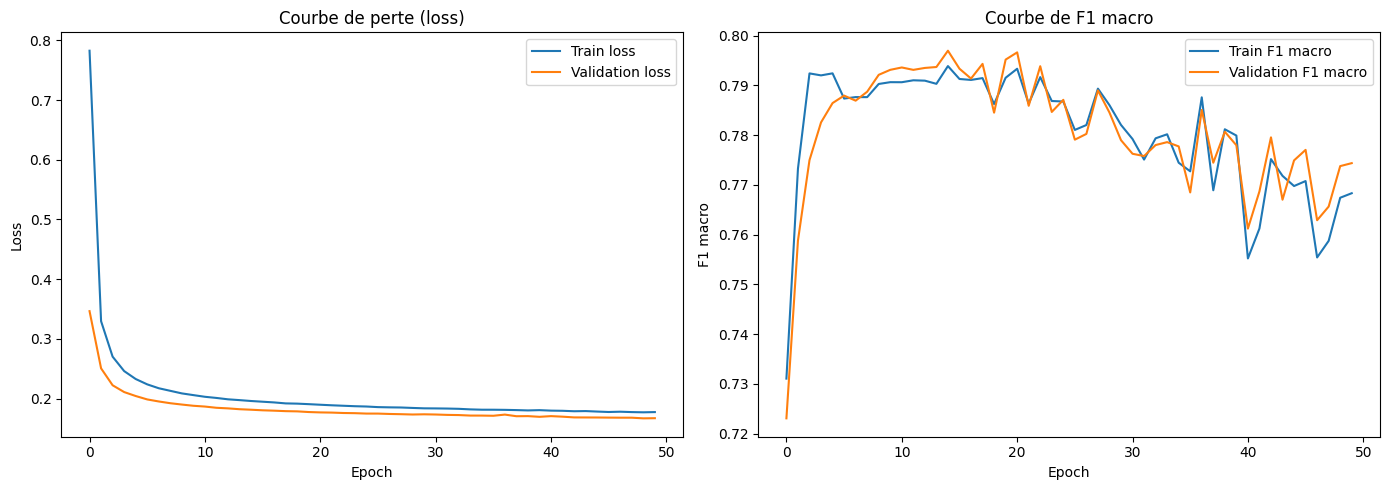

In [23]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import torch
import torch.nn as nn

BEST_HIDDEN = (128, 64)
BEST_LR = 0.0001
BEST_MAX_WEIGHT = 20
N_EPOCHS = 50

# Split simple train/val pour cette analyse (pas besoin de CV complète ici)
X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler().fit(X_tr)
X_tr = scaler.transform(X_tr)
X_val = scaler.transform(X_val)

class_weights = compute_class_weight("balanced", classes=np.unique(y_tr), y=y_tr)
class_weights = np.clip(class_weights, a_min=None, a_max=BEST_MAX_WEIGHT)
class_weights_t = torch.tensor(class_weights, dtype=torch.float32).to(device)

train_ds = TensorDataset(
    torch.tensor(X_tr, dtype=torch.float32),
    torch.tensor(y_tr, dtype=torch.long),
)
train_loader = DataLoader(train_ds, batch_size=2048, shuffle=True)

X_val_t = torch.tensor(X_val, dtype=torch.float32).to(device)
y_val_t = torch.tensor(y_val, dtype=torch.long)

# Échantillon du train (pour évaluer le score train sans repasser sur 1,7M lignes à chaque epoch)
sample_idx = np.random.choice(len(X_tr), size=min(50_000, len(X_tr)), replace=False)
X_tr_sample_t = torch.tensor(X_tr[sample_idx], dtype=torch.float32).to(device)
y_tr_sample = y_tr[sample_idx]

model = CyberDefenseMLP(n_features=X_tr.shape[1], n_classes=N_CLASSES, hidden=BEST_HIDDEN).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights_t)
optimizer = torch.optim.Adam(model.parameters(), lr=BEST_LR, weight_decay=1e-5)

history = {"train_loss": [], "val_loss": [], "train_f1": [], "val_f1": []}
for epoch in range(1, N_EPOCHS + 1):
    model.train()
    total_loss = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * xb.size(0)
    train_loss = total_loss / len(train_ds)

    # Évaluation (train échantillonné + validation) à chaque epoch
    model.eval()
    with torch.no_grad():
        val_logits = model(X_val_t)
        val_loss = criterion(val_logits, y_val_t.to(device)).item()
        val_pred = val_logits.argmax(dim=1).cpu().numpy()
        val_f1 = f1_score(y_val, val_pred, average="macro")

        train_logits = model(X_tr_sample_t)
        train_pred = train_logits.argmax(dim=1).cpu().numpy()
        train_f1 = f1_score(y_tr_sample, train_pred, average="macro")

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_f1"].append(train_f1)
    history["val_f1"].append(val_f1)

    if epoch % 5 == 0 or epoch == N_EPOCHS:
        print(f"epoch {epoch}/{N_EPOCHS} - train_loss: {train_loss:.4f} - val_loss: {val_loss:.4f} "
              f"- train_f1: {train_f1:.4f} - val_f1: {val_f1:.4f}")

# --- Les courbes ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history["train_loss"], label="Train loss")
axes[0].plot(history["val_loss"], label="Validation loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Courbe de perte (loss)")
axes[0].legend()

axes[1].plot(history["train_f1"], label="Train F1 macro")
axes[1].plot(history["val_f1"], label="Validation F1 macro")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("F1 macro")
axes[1].set_title("Courbe de F1 macro")
axes[1].legend()

plt.tight_layout()
plt.savefig('/kaggle/working/learning_curves.png', dpi=150)
plt.show()

## 20. Quantification de l'écart train/validation

On calcule l'écart moyen entre `train_f1` et `val_f1` sur l'ensemble des epochs, puis sur les 10
premières et les 10 dernières epochs après stabilisation. **Un écart qui diminue ou reste stable
dans le temps (et non qui croît) confirme l'absence de surapprentissage** — contrairement à un écart
qui s'accentuerait epoch après epoch, signe que le modèle mémorise le train au lieu de généraliser.


In [24]:
import numpy as np
gap = np.array(history["train_f1"]) - np.array(history["val_f1"])
print("Écart moyen :", gap.mean())
print("Écart sur les 10 dernières epochs :", gap[-10:].mean())
print("Écart sur les 10 premières epochs (après stabilisation) :", gap[10:20].mean())

Écart moyen : -0.00022762570542770978
Écart sur les 10 dernières epochs : -0.005125178822805309
Écart sur les 10 premières epochs (après stabilisation) : -0.002121322676513171


## 21. Entraînement final sur 100 % des données

Les hyperparamètres étant déjà validés (grid search + diagnostic d'overfitting ci-dessus), le
modèle final est **réentraîné sur l'intégralité du dataset préparé** (sans split train/val cette
fois) : on ne gaspille aucune donnée disponible pour la version qui sera réellement déployée. Le
`StandardScaler` final est lui aussi recalculé sur 100 % des données, et sera sauvegardé pour
reproduire exactement la même normalisation en production.


In [25]:
import joblib

FINAL_HIDDEN = (128, 64)
FINAL_LR = 0.0001
FINAL_MAX_WEIGHT = 20
FINAL_EPOCHS = 50

# Scaler final, calculé sur TOUT le dataset (plus de split ici)
final_scaler = StandardScaler().fit(X)
X_scaled = final_scaler.transform(X)

class_weights = compute_class_weight("balanced", classes=np.unique(y), y=y)
class_weights = np.clip(class_weights, a_min=None, a_max=FINAL_MAX_WEIGHT)
class_weights_t = torch.tensor(class_weights, dtype=torch.float32).to(device)

train_ds = TensorDataset(
    torch.tensor(X_scaled, dtype=torch.float32),
    torch.tensor(y, dtype=torch.long),
)
train_loader = DataLoader(train_ds, batch_size=2048, shuffle=True)

final_model = CyberDefenseMLP(n_features=X.shape[1], n_classes=N_CLASSES, hidden=FINAL_HIDDEN).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights_t)
optimizer = torch.optim.Adam(final_model.parameters(), lr=FINAL_LR, weight_decay=1e-5)

for epoch in range(1, FINAL_EPOCHS + 1):
    final_model.train()
    total_loss = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(final_model(xb), yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * xb.size(0)
    if epoch % 10 == 0 or epoch == FINAL_EPOCHS:
        print(f"epoch {epoch}/{FINAL_EPOCHS} - loss: {total_loss/len(train_ds):.4f}")

print("Entraînement final terminé.")

epoch 10/50 - loss: 0.1998
epoch 20/50 - loss: 0.1864
epoch 30/50 - loss: 0.1809
epoch 40/50 - loss: 0.1770
epoch 50/50 - loss: 0.1745
Entraînement final terminé.


## 22. Sauvegarde des artefacts de déploiement

Quatre fichiers sont nécessaires conjointement pour reproduire les prédictions en dehors de ce
notebook (sur le serveur de collecte, par exemple) — aucun ne suffit seul :

| Fichier | Rôle |
|---|---|
| `cyberdefense_mlp.pth` | Poids du réseau de neurones entraîné |
| `scaler.joblib` | `StandardScaler` ajusté sur les données d'entraînement (même normalisation en production) |
| `label_encoder.joblib` | Correspondance entre indices numériques et noms de familles d'attaques |
| `feature_columns.joblib` | Ordre exact des colonnes attendu par le modèle |

Voir la documentation complète du modèle pour le détail de la recherche d'hyperparamètres, les
résultats de validation croisée, et les tests de validation sur trafic réseau réel.


In [26]:
torch.save(final_model.state_dict(), '/kaggle/working/cyberdefense_mlp.pth')
joblib.dump(final_scaler, '/kaggle/working/scaler.joblib')
joblib.dump(le, '/kaggle/working/label_encoder.joblib')
joblib.dump(FEATURE_COLUMNS, '/kaggle/working/feature_columns.joblib')

print("Modèle et artefacts sauvegardés dans /kaggle/working/")

Modèle et artefacts sauvegardés dans /kaggle/working/
